# Creating Figures

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime

start_time = time.time()

In [2]:
import importlib.util
from pathlib import Path

module_path = Path("Endogenous-Retirement-Search-v3.py")
spec = importlib.util.spec_from_file_location("retirement_search", module_path)
retirement_search = importlib.util.module_from_spec(spec)
spec.loader.exec_module(retirement_search)

RetiringDeaton = retirement_search.RetiringDeaton

In [3]:
# +
CRRA = 1.0
DiscFac = 0.98
Rfree = 1.0
DisUtil = 1.0
T = 20
sigma_s = 0.0
sigma_t = 0.0
sigma_xi = 0.0
prob_opt = 1.0
smoothtype = 'type1'

aXtraMin = 1e-6
aXtraMax = 400.0
aXtraCount = 6000
aXtraExtra = () # this is additional points to add (for precision around know problematic areas)
aXtraNestFac = 1 # this is the times to nest

YWork = 20.0
YRet = 0.0 # normalized relative to work
TranShkStd = [0.000]*T
TranShkCount = 1
PermShkStd = [0.0]*T
PermShkCount = 1
TasteShkCount = 1
EGMCount = 7000
saveCommon = False #True #False
T_retire = 0 # not applicable, it's endogenous
T_cycle = T
LivPrb = [1.0]*T
PermGroFac = [1.0]*T
UnempPrb = 0.0
UnempPrbRet = 0.0
IncUnemp = 0.0
IncUnempRet = 0.0


retiring_params = {'CRRA' : CRRA,
                   'Rfree' : Rfree,
                   'DiscFac' : DiscFac,
                   'DisUtil' : DisUtil,
                   'T' : T,
                   'sigma_s' : sigma_s,
                   'sigma_t' : sigma_t,
                   'sigma_xi' : sigma_xi,
                   'prob_opt' : prob_opt,
                   'smoothtype' : smoothtype,
                   'aXtraMin' : aXtraMin,
                   'aXtraMax' : aXtraMax,
                   'aXtraCount' : aXtraCount,
                   'aXtraExtra' : aXtraExtra,
                   'aXtraNestFac' : aXtraNestFac,
                   'UnempPrb' : UnempPrb,
                   'UnempPrbRet' : UnempPrbRet,
                   'IncUnemp' : IncUnemp,
                   'IncUnempRet' : IncUnempRet,
                   'YWork' : YWork,
                   'YRet' : YRet,
                   'TranShkStd' : TranShkStd,
                   'TranShkCount' : TranShkCount,
                   'PermShkStd' : PermShkStd,
                   'PermShkCount' : PermShkCount,
                   'TasteShkCount' : TasteShkCount,
                   'EGMCount' : EGMCount,
                   'T_retire' : T_retire,
                   'T_cycle' : T_cycle,
                   'LivPrb' : LivPrb,
                   'PermGroFac' : PermGroFac,
                   'saveCommon' : saveCommon}
# -

In [4]:
retiring_params

{'CRRA': 1.0,
 'Rfree': 1.0,
 'DiscFac': 0.98,
 'DisUtil': 1.0,
 'T': 20,
 'sigma_s': 0.0,
 'sigma_t': 0.0,
 'sigma_xi': 0.0,
 'prob_opt': 1.0,
 'smoothtype': 'type1',
 'aXtraMin': 1e-06,
 'aXtraMax': 400.0,
 'aXtraCount': 6000,
 'aXtraExtra': (),
 'aXtraNestFac': 1,
 'UnempPrb': 0.0,
 'UnempPrbRet': 0.0,
 'IncUnemp': 0.0,
 'IncUnempRet': 0.0,
 'YWork': 20.0,
 'YRet': 0.0,
 'TranShkStd': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'TranShkCount': 1,
 'PermShkStd': [0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0,
  0.0],
 'PermShkCount': 1,
 'TasteShkCount': 1,
 'EGMCount': 7000,
 'T_retire': 0,
 'T_cycle': 20,
 'LivPrb': [1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  1.0],
 'PermGroFac': [1.0,
  1.0,
  1.0,
  1.0,
  1.0,
  

In [5]:
#model = dcegm.RetiringDeaton(saveCommon = True)
model = RetiringDeaton(**retiring_params)

In [6]:
model.solve()

Figures

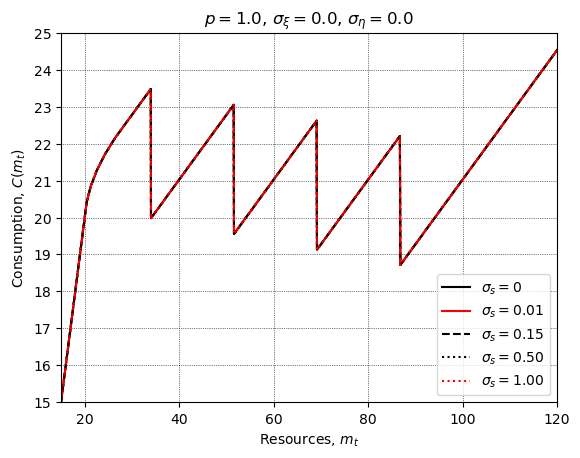

In [7]:
fig1_1_params = copy.deepcopy(retiring_params)
fig1_1_params['Rfree'] = 1.0
fig1_1_params['DiscFac'] = 0.98
fig1_1_params['prob_opt'] = 1.0
fig1_1_params['sigma_xi'] = 0.000
fig1_1_params['TasteShkCount'] = 1
fig1_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig1_1_params['T']
fig1_1_params['TranShkCount'] = 1
modelfig1_1 = RetiringDeaton(**fig1_1_params)
modelfig1_1.solve()

fig1_2_params = copy.deepcopy(fig1_1_params)
fig1_2_params['sigma_s'] = 0.01
modelfig1_2 = RetiringDeaton(**fig1_2_params)
modelfig1_2.solve()

fig1_3_params = copy.deepcopy(fig1_1_params)
fig1_3_params['sigma_s'] = 0.15
modelfig1_3 = RetiringDeaton(**fig1_3_params)
modelfig1_3.solve()

fig1_4_params = copy.deepcopy(fig1_1_params)
fig1_4_params['sigma_s'] = 0.5
modelfig1_4 = RetiringDeaton(**fig1_4_params)
modelfig1_4.solve()

fig1_5_params = copy.deepcopy(fig1_1_params)
fig1_5_params['sigma_s'] = 1.0
modelfig1_5 = RetiringDeaton(**fig1_5_params)
modelfig1_5.solve()

t=15

plt.plot(modelfig1_1.mGrid, modelfig1_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig1_2.mGrid, modelfig1_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig1_3.mGrid, modelfig1_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig1_4.mGrid, modelfig1_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig1_5.mGrid, modelfig1_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
# plt.savefig("../Figures/Figures_v3/p1_xi0_eta0.pdf", dpi=150)
plt.show()

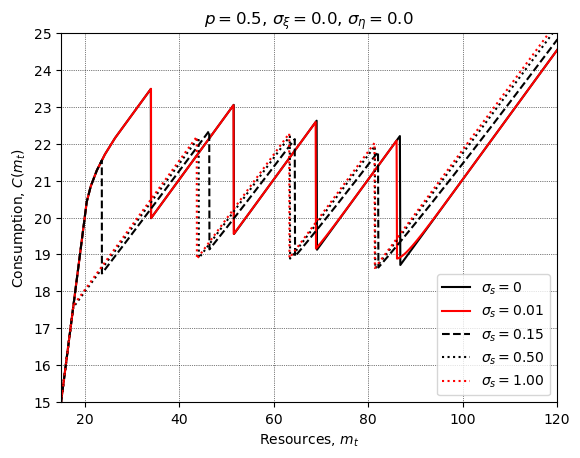

In [8]:
fig1a_1_params = copy.deepcopy(retiring_params)
fig1a_1_params['Rfree'] = 1.0
fig1a_1_params['DiscFac'] = 0.98
fig1a_1_params['prob_opt'] = 0.5
fig1a_1_params['sigma_xi'] = 0.000
fig1a_1_params['TasteShkCount'] = 1
fig1a_1_params['TranShkStd'] = [np.sqrt(0.000)]*fig1a_1_params['T']
fig1a_1_params['TranShkCount'] = 1
modelfig1a_1 = RetiringDeaton(**fig1a_1_params)
modelfig1a_1.solve()

fig1a_2_params = copy.deepcopy(fig1a_1_params)
fig1a_2_params['sigma_s'] = 0.01
modelfig1a_2 = RetiringDeaton(**fig1a_2_params)
modelfig1a_2.solve()

fig1a_3_params = copy.deepcopy(fig1a_1_params)
fig1a_3_params['sigma_s'] = 0.15
modelfig1a_3 = RetiringDeaton(**fig1a_3_params)
modelfig1a_3.solve()

fig1a_4_params = copy.deepcopy(fig1a_1_params)
fig1a_4_params['sigma_s'] = 0.5
modelfig1a_4 = RetiringDeaton(**fig1a_4_params)
modelfig1a_4.solve()

fig1a_5_params = copy.deepcopy(fig1a_1_params)
fig1a_5_params['sigma_s'] = 1.0
modelfig1a_5 = RetiringDeaton(**fig1a_5_params)
modelfig1a_5.solve()

t=15

plt.plot(modelfig1a_1.mGrid, modelfig1a_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig1a_2.mGrid, modelfig1a_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig1a_3.mGrid, modelfig1a_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig1a_4.mGrid, modelfig1a_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig1a_5.mGrid, modelfig1a_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 0.5$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = 0.0$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_s = 0$','$\sigma_s = 0.01$','$\sigma_s = 0.15$','$\sigma_s = 0.50$','$\sigma_s = 1.00$'],loc=4)
# plt.savefig("../Figures/Figures_v3/p0p5_xi0_eta0.pdf", dpi=150)
plt.show()

### Figure: Discretization vs Transitionmethod (no Taste shock, no search)

In [9]:
fig9_1_params = copy.deepcopy(retiring_params)
fig9_1_params['Rfree'] = 1.0
fig9_1_params['DiscFac'] = 0.98
fig9_1_params['prob_opt'] = 1.0
fig9_1_params['sigma_xi'] = 0.0
fig9_1_params['sigma_s'] = 0.0
fig9_1_params['TasteShkCount'] = 1
fig9_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig9_1_params['T']
fig9_1_params['TranShkCount'] = 1
fig9_1_params['IncomeDiscMethod'] = 'Discretize'

modelfig9_1 = RetiringDeaton(**fig9_1_params)
modelfig9_1.solve()

fig9_2_params = copy.deepcopy(fig9_1_params)
fig9_2_params['TranShkCount'] = 7
modelfig9_2 = RetiringDeaton(**fig9_2_params)
modelfig9_2.solve()

fig9_3_params = copy.deepcopy(fig9_1_params)
fig9_3_params['TranShkCount'] = 151
modelfig9_3 = RetiringDeaton(**fig9_3_params)
modelfig9_3.solve()

fig9_4_params = copy.deepcopy(fig9_1_params)
fig9_4_params['IncomeDiscMethod'] = 'TransitionMethod'
fig9_4_params['bGridMin'] = 0.0
fig9_4_params['bGridMax'] = 600.0
fig9_4_params['bGridCount'] = 500
fig9_4_params['mGridMin'] = 1e-4
fig9_4_params['mGridMax'] = 620.0
fig9_4_params['mGridCount'] = 510
fig9_4_params['IncUnemp_Std'] = 0.0
modelfig9_4 = RetiringDeaton(**fig9_4_params)
modelfig9_4.solve()

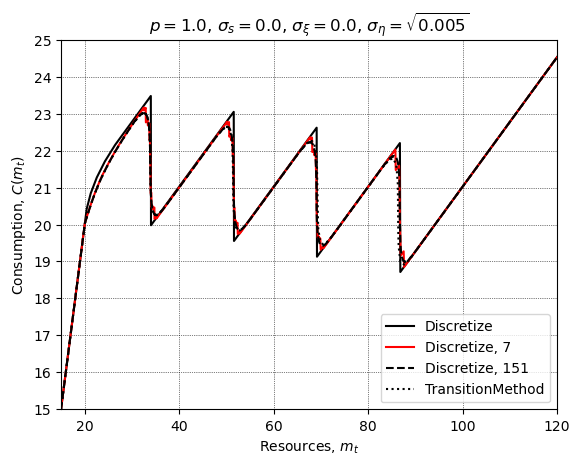

In [28]:
t=15

plt.plot(modelfig9_1.mGrid, modelfig9_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig9_2.mGrid, modelfig9_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig9_3.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig9_4.mGrid, modelfig9_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = \sqrt{0.005}$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['Discretize','Discretize, 7','Discretize, 151','TransitionMethod'],loc=4)
plt.savefig("../Figures/Figures_v3/IncomeDiscMethod.pdf", dpi=150)
plt.show()

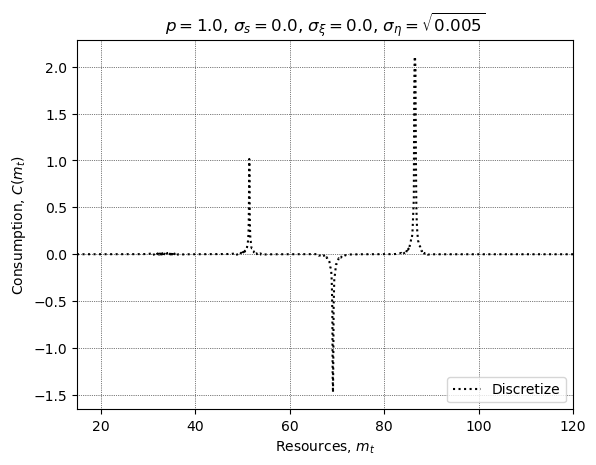

In [34]:
# plt.plot(modelfig9_1.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
# plt.plot(modelfig9_2.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
# plt.plot(modelfig9_3.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig9_4.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);
# plt.ylim([-0.5,0.5]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = \sqrt{0.005}$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
# plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['Discretize','Discretize, 7','Discretize, 151','TransitionMethod'],loc=4)
# plt.savefig("../Figures/Figures_v3/IncomeDiscMethod.pdf", dpi=150)
plt.show()

### Figure: Convergence of discretization vs Transition method (with solve times)

Isolates **phantom kinks** from income discretization (no search, no taste shocks, $p=1$), with $\sigma_\eta=\sqrt{0.005}$ as in the main-text income figure. Coarse $N$ injects spurious non-monotonicities; fine $N$ or the transition matrix removes them. Pointwise gaps vs $N=151$ are a secondary diagnostic only ($N=151$ is still discrete, not continuous truth) and are horizon-dependent—do not treat max abs.\ vs $151$ as the success criterion. Solve times show the cost of pushing $N$ high vs TM. Note: at substantially larger $\sigma_\eta$ (e.g.\ $2\sqrt{0.005}$), a fixed TM $(b,m)$ grid needs widening/refinement.

In [ ]:
t = 15
sig = np.sqrt(0.005)  # matches main-text fig (IncomeDiscMethod); not 2*sqrt

conv_base = copy.deepcopy(retiring_params)
conv_base['Rfree'] = 1.0
conv_base['DiscFac'] = 0.98
conv_base['prob_opt'] = 1.0
conv_base['sigma_xi'] = 0.0
conv_base['sigma_s'] = 0.0
conv_base['TasteShkCount'] = 1
conv_base['TranShkStd'] = [sig] * conv_base['T']
conv_base['TranShkCount'] = 1
conv_base['IncomeDiscMethod'] = 'Discretize'

disc_counts = [1, 7, 31, 151]
disc_models = {}
disc_times = {}
for n in disc_counts:
    p = copy.deepcopy(conv_base)
    p['TranShkCount'] = n
    m = RetiringDeaton(**p)
    t0 = time.perf_counter()
    m.solve()
    disc_times[n] = time.perf_counter() - t0
    disc_models[n] = m

# Transition-matrix integration
p = copy.deepcopy(conv_base)
p['IncomeDiscMethod'] = 'TransitionMethod'
p['bGridMin'] = 0.0
p['bGridMax'] = 600.0
p['bGridCount'] = 500
p['mGridMin'] = 1e-4
p['mGridMax'] = 620.0
p['mGridCount'] = 510
p['IncUnemp_Std'] = 0.0
tm_model = RetiringDeaton(**p)
t0 = time.perf_counter()
tm_model.solve()
tm_time = time.perf_counter() - t0

# Accuracy relative to the 151-point discretized reference
m_common = np.linspace(15, 120, 2000)
ref = np.interp(m_common, disc_models[151].mGrid, disc_models[151].solution[t].ChoiceSols[1].C)


def max_abs_dev(model):
    c = np.interp(m_common, model.mGrid, model.solution[t].ChoiceSols[1].C)
    return np.max(np.abs(c - ref))


def mean_abs_dev(model):
    c = np.interp(m_common, model.mGrid, model.solution[t].ChoiceSols[1].C)
    return np.mean(np.abs(c - ref))


print(f"sigma_eta = {sig:.6f}  (= sqrt(0.005));  t = {t}")
print("Method            | gridpoints | solve time (s) | max abs dev | mean abs dev")
print("-" * 78)
for n in disc_counts:
    print(f"Discretize        | {n:>10d} | {disc_times[n]:>14.3f} | {max_abs_dev(disc_models[n]):>11.4f} | {mean_abs_dev(disc_models[n]):>12.4f}")
print(f"TransitionMethod  | {'-':>10} | {tm_time:>14.3f} | {max_abs_dev(tm_model):>11.4f} | {mean_abs_dev(tm_model):>12.4f}")


sigma_eta = 0.070711  (= sqrt(0.005));  t = 15
Method            | gridpoints | solve time (s) | max abs dev | mean abs dev
------------------------------------------------------------------------------
Discretize        |          1 |          0.589 |      2.4441 |       0.0781
Discretize        |          7 |          0.770 |      0.3348 |       0.0184
Discretize        |         31 |          1.799 |      0.2600 |       0.0055
Discretize        |        151 |          6.229 |      0.0000 |       0.0000
Discretize        |        501 |         19.189 |      0.0613 |       0.0012
TransitionMethod  |          - |          0.846 |      2.1052 |       0.0231


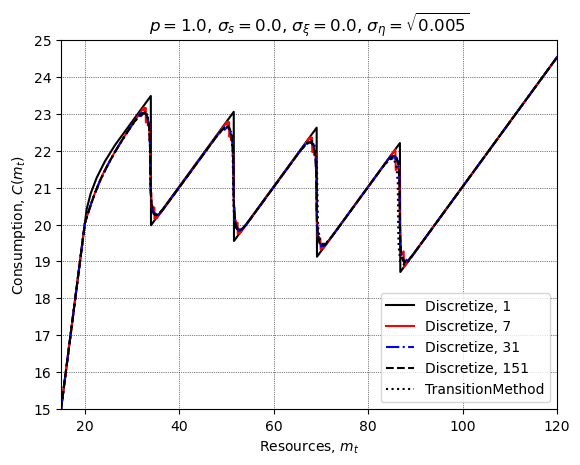

In [31]:
plt.figure()
plt.plot(disc_models[1].mGrid, disc_models[1].solution[t].ChoiceSols[1].C, color='k', linestyle='-')
plt.plot(disc_models[7].mGrid, disc_models[7].solution[t].ChoiceSols[1].C, color='r', linestyle='-')
plt.plot(disc_models[31].mGrid, disc_models[31].solution[t].ChoiceSols[1].C, color='b', linestyle='-.')
plt.plot(disc_models[151].mGrid, disc_models[151].solution[t].ChoiceSols[1].C, color='k', linestyle='--')
plt.plot(tm_model.mGrid, tm_model.solution[t].ChoiceSols[1].C, color='k', linestyle=':')
plt.xlim([15, 120]); plt.ylim([15, 25])
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\\sigma_s = 0.0$, $\\sigma_{\\xi} = 0.0$, $\\sigma_{\\eta} = \\sqrt{0.005}$")
plt.grid(color='k', linestyle=':', linewidth=0.5)
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['Discretize, 1', 'Discretize, 7', 'Discretize, 31', 'Discretize, 151', 'TransitionMethod'], loc=4)
plt.savefig("../Figures/Figures_v3/IncomeDiscMethod_Convergence.pdf", dpi=150)
plt.show()

### Test: Adding search

In [14]:
fig9b_1_params = copy.deepcopy(retiring_params)
fig9b_1_params['Rfree'] = 1.0
fig9b_1_params['DiscFac'] = 0.98
fig9b_1_params['prob_opt'] = 1.0
fig9b_1_params['sigma_xi'] = 0.0
fig9b_1_params['sigma_s'] = 0.5
fig9b_1_params['TasteShkCount'] = 1
fig9b_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig9b_1_params['T']
fig9b_1_params['TranShkCount'] = 1
fig9b_1_params['IncomeDiscMethod'] = 'Discretize'

modelfig9b_1 = RetiringDeaton(**fig9b_1_params)
modelfig9b_1.solve()

fig9b_2_params = copy.deepcopy(fig9b_1_params)
fig9b_2_params['TranShkCount'] = 7
modelfig9b_2 = RetiringDeaton(**fig9b_2_params)
modelfig9b_2.solve()

fig9b_3_params = copy.deepcopy(fig9b_1_params)
fig9b_3_params['TranShkCount'] = 151
modelfig9b_3 = RetiringDeaton(**fig9b_3_params)
modelfig9b_3.solve()

fig9b_4_params = copy.deepcopy(fig9b_1_params)
fig9b_4_params['IncomeDiscMethod'] = 'TransitionMethod'
fig9b_4_params['bGridMin'] = 0.0
fig9b_4_params['bGridMax'] = 600.0
fig9b_4_params['bGridCount'] = 500
fig9b_4_params['mGridMin'] = 1e-4
fig9b_4_params['mGridMax'] = 620.0
fig9b_4_params['mGridCount'] = 510
fig9b_4_params['IncUnemp_Std'] = 0.0
modelfig9b_4 = RetiringDeaton(**fig9_4_params)
modelfig9b_4.solve()

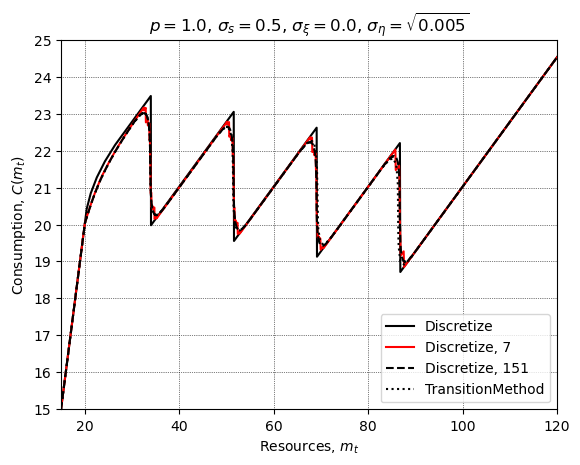

In [32]:
t=15

plt.plot(modelfig9b_1.mGrid, modelfig9b_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig9b_2.mGrid, modelfig9b_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig9b_3.mGrid, modelfig9b_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig9b_4.mGrid, modelfig9b_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.5$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = \sqrt{0.005}$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['Discretize','Discretize, 7','Discretize, 151','TransitionMethod'],loc=4)
# plt.savefig("../Figures/Figures_v3/IncomeDiscMethod.pdf", dpi=150)
plt.show()

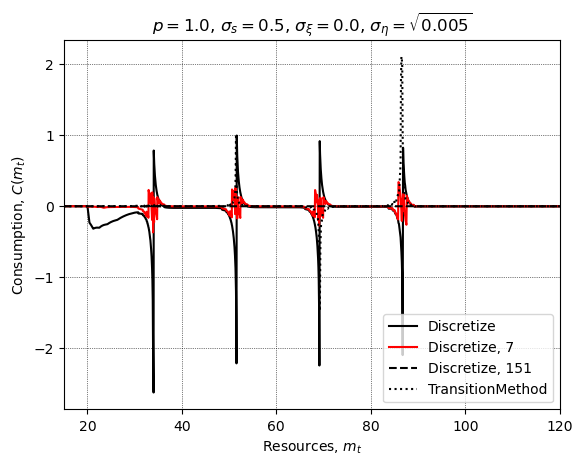

In [33]:
plt.plot(modelfig9b_1.mGrid, modelfig9b_3.solution[t].ChoiceSols[1].C - modelfig9b_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig9_2.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9b_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig9b_3.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9b_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig9b_4.mGrid, modelfig9_3.solution[t].ChoiceSols[1].C - modelfig9b_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.xlim([15,120]);
# plt.ylim([-0.5,0.5]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.5$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = \sqrt{0.005}$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
# plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['Discretize','Discretize, 7','Discretize, 151','TransitionMethod'],loc=4)
# plt.savefig("../Figures/Figures_v3/IncomeDiscMethod.pdf", dpi=150)
plt.show()

In [16]:
stop

NameError: name 'stop' is not defined

### Figure: varying transitory income shock (no Taste shock, no search)

In [ ]:
fig10_1_params = copy.deepcopy(retiring_params)
fig10_1_params['Rfree'] = 1.0
fig10_1_params['DiscFac'] = 0.98
fig10_1_params['prob_opt'] = 1.0
fig10_1_params['sigma_xi'] = 0.0
fig10_1_params['sigma_s'] = 0.0
fig10_1_params['TasteShkCount'] = 1
fig10_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig10_1_params['T']
fig10_1_params['TranShkCount'] = 1
fig10_1_params['IncomeDiscMethod'] = 'TransitionMethod'
fig10_1_params['bGridMin'] = 0.0
fig10_1_params['bGridMax'] = 600.0
fig10_1_params['bGridCount'] = 500
fig10_1_params['mGridMin'] = 1e-4
fig10_1_params['mGridMax'] = 620.0
fig10_1_params['mGridCount'] = 510
fig10_1_params['IncUnemp_Std'] = 0.0

modelfig10_1 = RetiringDeaton(**fig10_1_params)
modelfig10_1.solve()

fig10_2_params = copy.deepcopy(fig10_1_params)
fig10_2_params['TranShkStd'] = [2 * np.sqrt(0.005)]*fig10_1_params['T']
modelfig10_2 = RetiringDeaton(**fig10_2_params)
modelfig10_2.solve()

fig10_3_params = copy.deepcopy(fig10_1_params)
fig10_3_params['TranShkStd'] = [2 * np.sqrt(0.005)]*fig10_1_params['T']
fig10_3_params['IncomeDiscMethod'] = 'Discretize'
fig10_3_params['TranShkCount'] = 151
modelfig10_3 = RetiringDeaton(**fig10_3_params)
modelfig10_3.solve()

fig10_4_params = copy.deepcopy(fig10_1_params)
fig10_4_params['TranShkStd'] = [4 * np.sqrt(0.005)]*fig10_1_params['T']
modelfig10_4 = RetiringDeaton(**fig10_4_params)
modelfig10_4.solve()

fig10_5_params = copy.deepcopy(fig10_1_params)
fig10_5_params['TranShkStd'] = [4 * np.sqrt(0.005)]*fig10_1_params['T']
fig10_5_params['IncomeDiscMethod'] = 'Discretize'
fig10_5_params['TranShkCount'] = 151
modelfig10_5 = RetiringDeaton(**fig10_5_params)
modelfig10_5.solve()



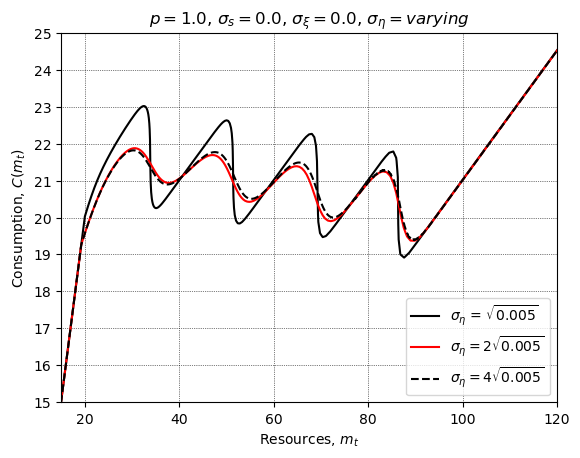

In [ ]:
t=15

plt.plot(modelfig10_1.mGrid, modelfig10_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig10_2.mGrid, modelfig10_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig10_3.mGrid, modelfig10_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
# plt.plot(modelfig10_4.mGrid, modelfig10_4.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
# plt.plot(modelfig10_5.mGrid, modelfig10_5.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = varying$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{\eta}$ = $\sqrt{0.005}$','$\sigma_{\eta} = 2 \sqrt{0.005}$', '$\sigma_{\eta} = 4 \sqrt{0.005}$'],loc=4)
plt.savefig("../Figures/Figures_v3/IncomeDiscMethod_TranShock.pdf", dpi=150)
plt.show()

### Figure varying permanent income shock (no Taste shock, no search) NOT IMPLEMENTED YET

In [ ]:
fig11_1_params = copy.deepcopy(retiring_params)
fig11_1_params['Rfree'] = 1.0
fig11_1_params['DiscFac'] = 0.98
fig11_1_params['prob_opt'] = 1.0
fig11_1_params['sigma_xi'] = 0.0
fig11_1_params['sigma_s'] = 0.0
fig11_1_params['TasteShkCount'] = 1
fig11_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig11_1_params['T']
fig11_1_params['TranShkCount'] = 1
fig11_1_params['IncomeDiscMethod'] = 'TransitionMethod'
fig11_1_params['bGridMin'] = 0.0
fig11_1_params['bGridMax'] = 600.0
fig11_1_params['bGridCount'] = 500
fig11_1_params['mGridMin'] = 1e-4
fig11_1_params['mGridMax'] = 620.0
fig11_1_params['mGridCount'] = 510
fig11_1_params['IncUnemp_Std'] = 0.0

modelfig11_1 = RetiringDeaton(**fig11_1_params)
modelfig11_1.solve()

fig11_2_params = copy.deepcopy(fig11_1_params)
fig11_2_params['PermShkStd'] = [0.1]*fig11_1_params['T']
fig11_2_params['PermShkCount'] = 31
modelfig11_2 = RetiringDeaton(**fig11_2_params)
modelfig11_2.solve()

fig11_2b_params = copy.deepcopy(fig11_1_params)
fig11_2b_params['PermShkStd'] = [0.1]*fig11_1_params['T']
fig11_2b_params['PermShkCount'] = 31
fig11_2b_params['TranShkCount'] = 31
fig11_2b_params['IncomeDiscMethod'] = 'Discretize'
modelfig11_2b = RetiringDeaton(**fig11_2b_params)
modelfig11_2b.solve()

fig11_3_params = copy.deepcopy(fig11_1_params)
fig11_3_params['PermShkStd'] = [0.2]*fig11_1_params['T']
fig11_3_params['PermShkCount'] = 31
modelfig11_3 = RetiringDeaton(**fig11_3_params)
modelfig11_3.solve()

fig11_3b_params = copy.deepcopy(fig11_1_params)
fig11_3b_params['PermShkStd'] = [0.2]*fig11_1_params['T']
fig11_3b_params['PermShkCount'] = 31
fig11_3b_params['TranShkCount'] = 31
fig11_3b_params['IncomeDiscMethod'] = 'Discretize'
modelfig11_3b = RetiringDeaton(**fig11_3b_params)
modelfig11_3b.solve()


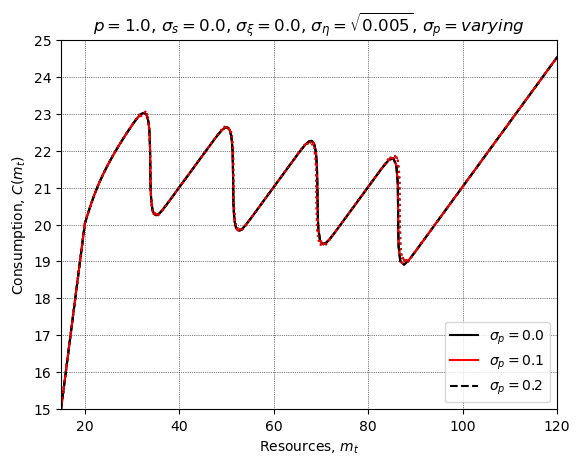

In [ ]:
t=15

plt.plot(modelfig11_1.mGrid, modelfig11_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig11_2.mGrid, modelfig11_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig11_3.mGrid, modelfig11_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.plot(modelfig11_2b.mGrid, modelfig11_2b.solution[t].ChoiceSols[1].C,color='k',linestyle=':')
plt.plot(modelfig11_3b.mGrid, modelfig11_3b.solution[t].ChoiceSols[1].C,color='r',linestyle=':')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_p = varying$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{p} = 0.0$','$\sigma_{p} = 0.1$','$\sigma_{p} = 0.2$'],loc=4)
plt.savefig("../Figures/Figures_v3/IncomeDiscMethod_PermShock.pdf", dpi=150)
plt.show()

### Figure varying unemployment shock (no Taste shock, no search)

In [ ]:
fig12_1_params = copy.deepcopy(retiring_params)
fig12_1_params['Rfree'] = 1.0
fig12_1_params['DiscFac'] = 0.98
fig12_1_params['prob_opt'] = 1.0
fig12_1_params['sigma_xi'] = 0.0
fig12_1_params['sigma_s'] = 0.0
fig12_1_params['TasteShkCount'] = 1
fig12_1_params['TranShkStd'] = [np.sqrt(0.005)]*fig12_1_params['T']
fig12_1_params['TranShkCount'] = 1
fig12_1_params['IncomeDiscMethod'] = 'TransitionMethod'
fig12_1_params['bGridMin'] = 0.0
fig12_1_params['bGridMax'] = 600.0
fig12_1_params['bGridCount'] = 500
fig12_1_params['mGridMin'] = 1e-4
fig12_1_params['mGridMax'] = 620.0
fig12_1_params['mGridCount'] = 510
fig12_1_params['IncUnemp_Std'] = 0.0

modelfig12_1 = RetiringDeaton(**fig12_1_params)
modelfig12_1.solve()

fig12_2_params = copy.deepcopy(fig12_1_params)
fig12_2_params['UnempPrb'] = 0.05
fig12_2_params['IncUnemp'] = 0.3
fig12_2_params['IncUnemp_Std'] = 0.1
modelfig12_2 = RetiringDeaton(**fig12_2_params)
modelfig12_2.solve()

fig12_3_params = copy.deepcopy(fig12_1_params)
fig12_3_params['UnempPrb'] = 0.1
fig12_3_params['IncUnemp'] = 0.3
fig12_3_params['IncUnemp_Std'] = 0.1
modelfig12_3 = RetiringDeaton(**fig12_3_params)
modelfig12_3.solve()

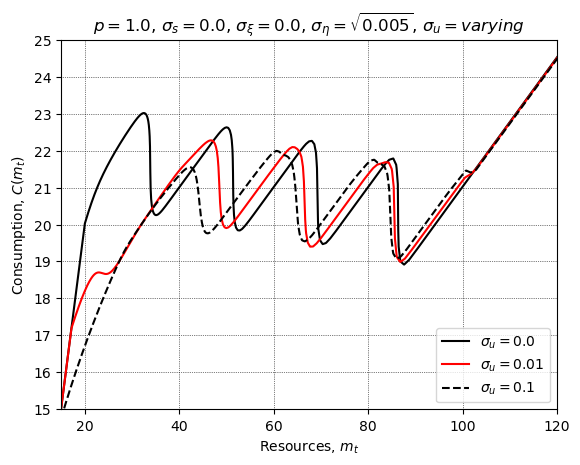

In [ ]:
t=15

plt.plot(modelfig12_1.mGrid, modelfig12_1.solution[t].ChoiceSols[1].C,color='k',linestyle='-')
plt.plot(modelfig12_2.mGrid, modelfig12_2.solution[t].ChoiceSols[1].C,color='r',linestyle='-')
plt.plot(modelfig12_3.mGrid, modelfig12_3.solution[t].ChoiceSols[1].C,color='k',linestyle='--')
plt.xlim([15,120]);plt.ylim([15,25]);
plt.xlabel("Resources, $m_t$"); plt.ylabel("Consumption, $C(m_t)$")
plt.title("$p = 1.0$, $\sigma_s = 0.0$, $\sigma_{\\xi} = 0.0$, $\sigma_{\eta} = \sqrt{0.005}$, $\sigma_u = varying$")
plt.grid(color='k', linestyle=':', linewidth=0.5);
plt.yticks(np.arange(15, 26, step=1.0))
plt.legend(['$\sigma_{u} = 0.0$','$\sigma_{u} = 0.01$','$\sigma_{u} = 0.1$'],loc=4)
plt.savefig("../Figures/Figures_v3/IncomeDiscMethod_UnempShock.pdf", dpi=150)
plt.show()